                                    PROJEKT ZALICZENIOWY - WIZUALIZACJA DANYCH
                                     Raport na podstawie danych 'pokemon.csv'
                                     Zespół: Piotr Białek, Łukasz Kubicki, Małgorzata Teślak

In [186]:
# Wczytanie bibliotek

import pandas as pd
import numpy as np
import skimpy as skim
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox
from scipy.stats.contingency import association

In [18]:
# Wczytanie danych z pliku CSV
dane = pd.read_csv('pokemon.csv')

In [19]:
skim.skim(dane)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 800    │ │ int64       │ 9     │                                                          │
│ │ Number of columns │ 13     │ │ string      │ 3     │                                                          │
│ └───────────────────┴────────┘ │ bool        │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column         ┃ NA   ┃ NA %   ┃ mean    ┃ sd      ┃ p0    ┃ p25     ┃ p50     ┃ p75     ┃ p100  ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━┩  │
│ │       #        │    0 │      0 │   362.8 │   208.3 │     1 │   184.8 │   364.5 │   539.2 │   721 │ ▇▇▇▇▇▇  │  │
│ │     Total      │    0 │      0 │   435.1 │     120 │   180 │     330 │     450 │     515 │   780 │ ▂▇▇▇▃▁  │  │
│ │       HP       │    0 │      0 │   69.26 │   25.53 │     1 │      50 │      65 │      80 │   255 │   ▁▇▂   │  │
│ │     Attack     │    0 │      0 │      79 │   32.46 │     5 │      55 │      75 │     100 │   190 │  ▂▇▇▅▂  │  │
│ │    Defense     │    0 │      0 │   73.84 │   31.18 │     5 │      50 │      70 │      90 │   230 │  ▂▇▅▁   │  │
│ │    Sp. Atk     │    0 │      0 │   72.82 │   32.72 │    10 │   49.75 │      65 │      95 │   194 │  ▃▇▅▃▁  │  │
│ │    Sp. Def     │    0 │      0 │    71.9 │   27.83 │    20 │      50 │      70 │      90 │   230 │  ▅▇▃▁   │  │
│ │     Speed      │    0 │      0 │   68.28 │   29.06 │     5 │      45 │      65 │      90 │   180 │  ▃▇▇▅▁  │  │
│ │   Generation   │    0 │      0 │   3.324 │   1.661 │     1 │       2 │       3 │       5 │     6 │ ▇▅▇▆▇▃  │  │
│ └────────────────┴──────┴────────┴─────────┴─────────┴───────┴─────────┴─────────┴─────────┴───────┴─────────┘  │
│                                                      bool                                                       │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column                          ┃ true             ┃ true rate                      ┃ hist                 ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │            Legendary            │               65 │                          0.081 │        ▇    ▁        │  │
│ └─────────────────────────────────┴──────────────────┴────────────────────────────────┴──────────────────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃        ┃     ┃       ┃          ┃            ┃           ┃           ┃ chars per  ┃ words per ┃ total      ┃  │
│ ┃ column ┃ NA  ┃ NA %  ┃ shortest ┃ longest    ┃ min       ┃ max       ┃ row        ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩  │
│ │  Name  │   0 │     0 │   Muk    │ CharizardM │ Aboma

In [20]:
# Wyświetlamy podstawowe informacje na temat typów kolumn z danymi
dane.info()
print('\n')
print('Rozmiar zbioru danych',dane.shape)

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 89.3 KB


Rozmiar zbioru danych (800, 13)


In [21]:
#wyswietlimy pierwsze 5 wierszy danych
dane.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [22]:
#sprawdzimy czy w danych występują wartości puste
dane.isna().any()

#             False
Name          False
Type 1        False
Type 2         True
Total         False
HP            False
Attack        False
Defense       False
Sp. Atk       False
Sp. Def       False
Speed         False
Generation    False
Legendary     False
dtype: bool

Jedyną zmienną w rozważanym zbiorze danych, która nie ma wszystkich wartości, jest zmienna Type 2. Sprawdzimy, czy pokemony, mające zdefiniowane 2 typy mają znacząco różne wartości pozostałych zmiennych niż pokemony, które mają tylko jeden typ.

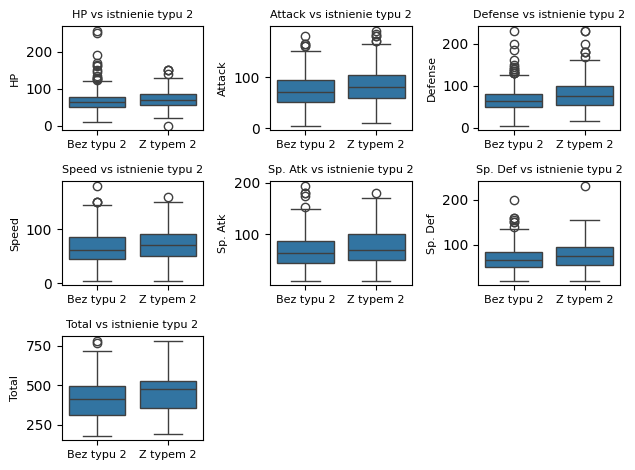

In [38]:
#pomocnicza kolumna, która będzie informować czy w danym wierszu istnieje wartość w kolumnie Type 2
dane['Type2Exists'] = dane['Type 2'].notna()
#lista zmiennych, które będziemy sprawdzać w zależności od istnienia typu 2
checking_variables = ["HP", "Attack", "Defense", "Speed", "Sp. Atk", "Sp. Def", "Total"]

for i in range(len(checking_variables)):
    checking_variable = checking_variables[i]
    plt.subplot(3, 3, i + 1)
    chart = sns.boxplot(data=dane, x="Type2Exists", y=checking_variable)
    plt.title(checking_variable + ' vs istnienie typu 2', fontsize=8)
    plt.xlabel("")
    plt.xticks([False, True], ["Bez typu 2", "Z typem 2"])
    plt.xticks(fontsize=8)
    plt.ylabel(checking_variable, fontsize=8)
    

plt.tight_layout()
plt.show()

48% pokemonów nie ma zdefiniowanego typu 2. Jest to reprezentatywna grupa danych/pokemonów, aby porównać ją z grupą pokemonów, które mają ów typ zdefiniowany. Z wykresów powyższych, porównujących rozkład takich zmiennych jak HP, Attack, Defense, Speed, Sp.Atk and Sp.Def versus posiadanie typu 2, możemy zauważyć, iż pokemony mające 2 typy wykazują się lekko większymi wartościami dla badanych cech.

Przyjrzymy się teraz w jakiej relacji są do siebie zmienne HP, Attack, Defense, Speed, Sp.Atk oraz Sp.Def. Chcemy sprawdzić, czy istnieje jakaś zależność między tymi zmiennymi.

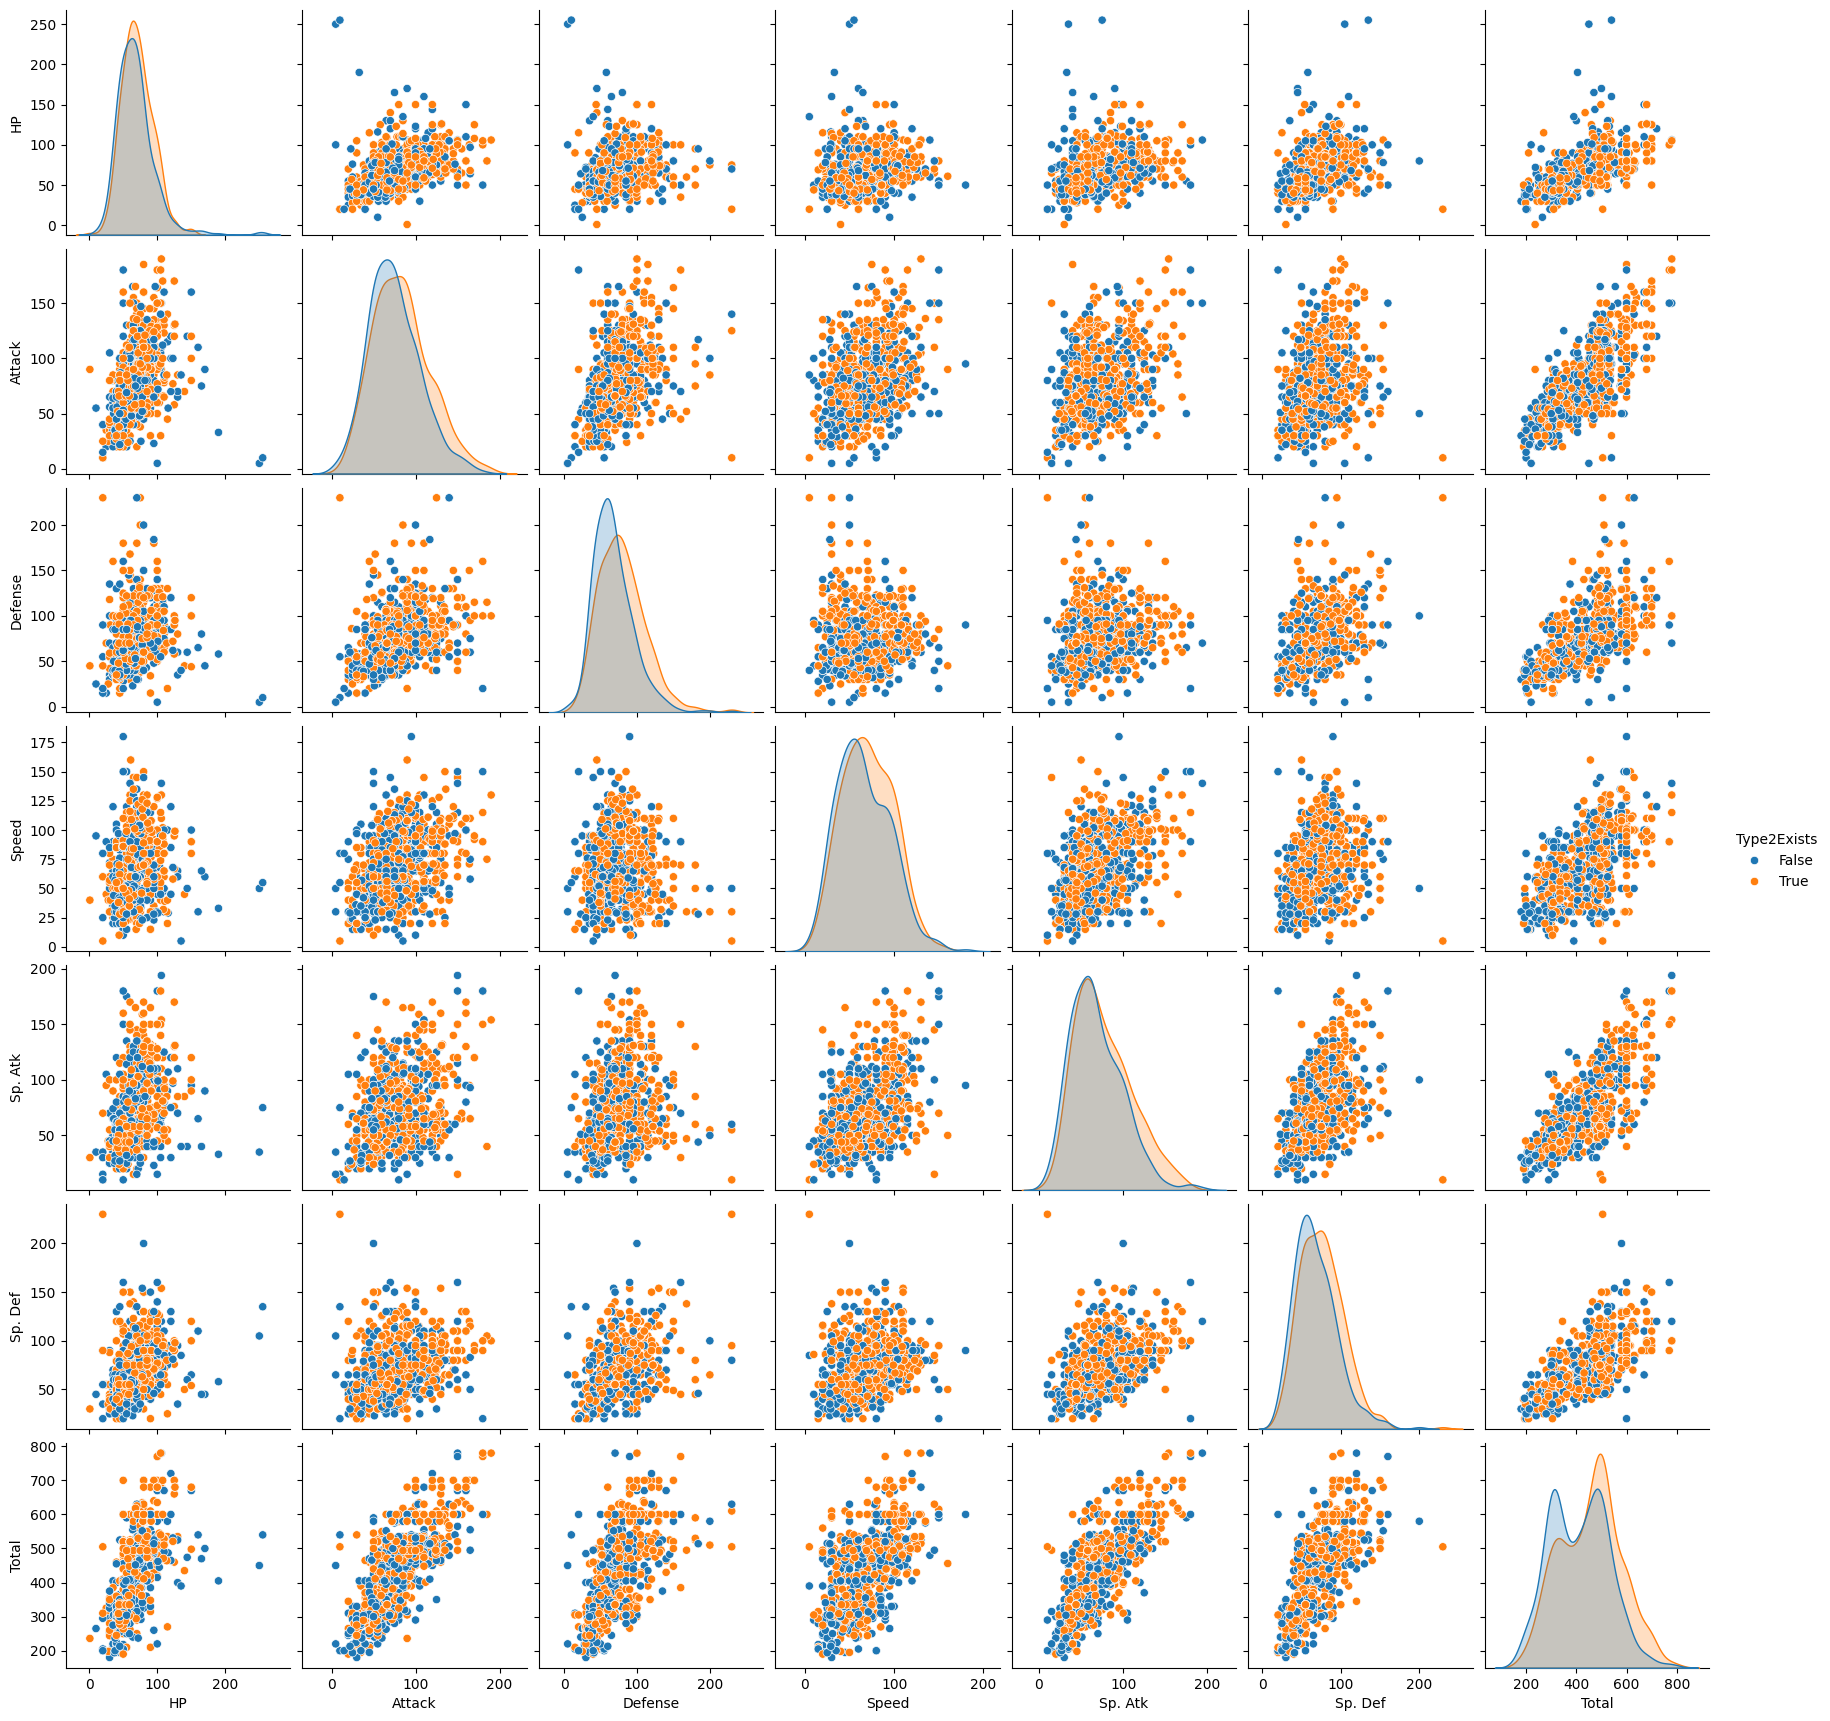

In [24]:
sns.pairplot(dane, vars=['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def', 'Total'], hue='Type2Exists')


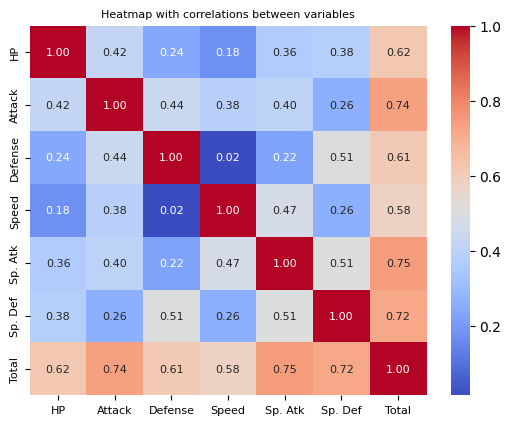

In [36]:
chart = sns.heatmap(dane[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def', 'Total']].corr(), annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 8});
plt.title("Heatmap with correlations between variables", fontsize=8)
chart.set_xticklabels(chart.get_xticklabels(), fontsize=8)
chart.set_yticklabels(chart.get_yticklabels(), fontsize=8)
plt.show()

Z powyższej macierzy wykresów oraz z macierzy cieplnej z korelacją między zmiennymi wynika, iż nie ma silnej zależności między zmiennymi HP, Attack, Defense, Speed, Sp.At oraz SP. Defense. Natomiast istnieje istotna korelacja pomiędzy tymi zmiennymi, a zmienną Total. Przede wszystkich wartości Attacku mają największy wpływ na wartość Total.

Możemy jeszcze zbadać korelację tych zmiennych metodą Kendalla

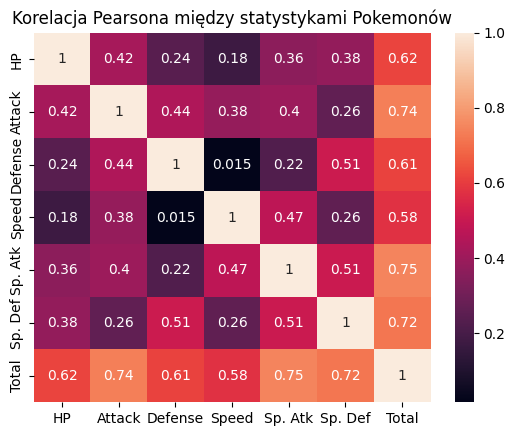

In [183]:
korelacja_pearsona = dane[checking_variables].corr(method="pearson")
sns.heatmap(korelacja_pearsona, annot=True)
plt.title("Korelacja Pearsona między statystykami Pokemonów")
plt.show()

Wynik korelacji Pearsona potwierdza poprzedni wniosek.

Sprawdzimy teraz kształt rozkładu badanych zmiennych: HP, Attack, Defense, Speed, Sp.Atk, Sp.Def and Total

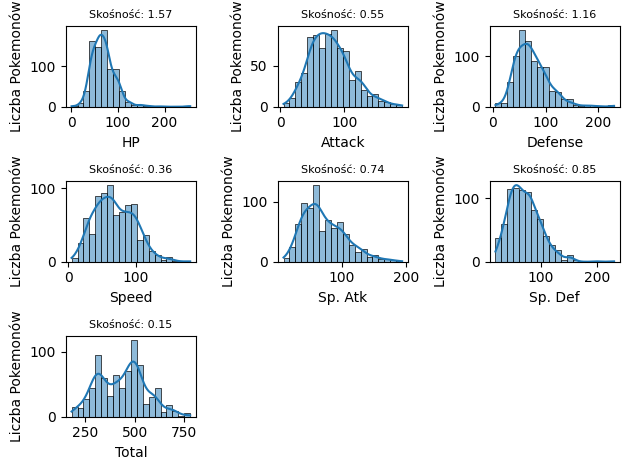

In [39]:
for i in range(len(checking_variables)):
    checking_variable = checking_variables[i]

    plt.subplot(3, 3, i + 1)
    sns.histplot(data=dane, x=checking_variable, bins=20, kde=True)

    skosnosc = dane[checking_variable].skew()

    plt.title(f"Skośność: {skosnosc:.2f}", fontsize = 8)
    plt.xlabel(checking_variable)
    plt.ylabel("Liczba Pokemonów")

plt.tight_layout()
plt.show()

W kształcie rozkładu każdej zmiennej widzimy prawostronną skośność - dłuższe ogony z prawej strony. Potwierdzają to również dodatnie wartości wyliczonej statystyki skośności. Dlatego w przypadku budowania modelu na tych zmiennych warto rozważyć transformację tych zmiennych, np. znormalizować je transformacją Boxa - Coxa.

Sprawdzimy teraz jak kształtują się poszczególne atrybuty per typ 1 pokemona.

In [27]:
#zsumujemy wartości zmiennych wliczanych do Total w zależności od typu 1 Pokemona
zmienne_wplywajace_na_total = ["Total", "HP", "Attack", "Defense", "Speed", "Sp. Atk", "Sp. Def"]
zsumowane_dane = dane.groupby('Type 1')[zmienne_wplywajace_na_total].sum().reset_index()

In [188]:
#wyliczymy udział poszczególnych zmiennych w stosunku do wartości Total dla każdego typu 1 Pokemona
for i in range(len(zmienne_wplywajace_na_total)):
    zmienna = zmienne_wplywajace_na_total[i]
    zsumowane_dane[f'{zmienna}_udzial'] = zsumowane_dane[zmienna] / zsumowane_dane['Total']


<Axes: title={'center': 'Udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona'}, xlabel='Type 1'>

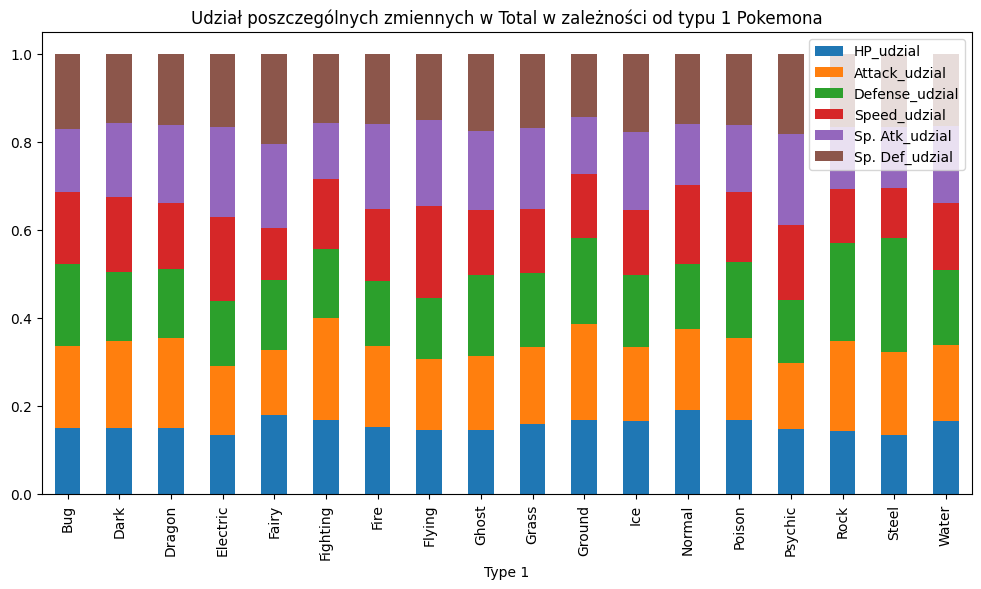

In [29]:
#narysujemy bar plot pokazujący udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona
zsumowane_dane_udzialy = zsumowane_dane[["Type 1", "HP_udzial", "Attack_udzial", "Defense_udzial", "Speed_udzial", "Sp. Atk_udzial", "Sp. Def_udzial"]]
zsumowane_dane_udzialy.plot(kind='bar', stacked=True, x='Type 1', title='Udział poszczególnych zmiennych w Total w zależności od typu 1 Pokemona', legend=True, figsize=(12, 6))

Z powyższego wykresu możemy wyczytać, które zmienne mają największy lub najmniejszy wpływ na wartość Total danego pokemona. Dla przykładu możemy zauważyć, że na Total pokemonów typu Steel największy wpływ ma obrona/Defense, a jednocześnie Speed ma najmniejszy wpływ. Natomiast na wartość Total pokemonów typu Fighting i Ground największe znaczenie ma Attack. Uwaga: największe/najmniejsze udziały poszczególnej zmiennej na wartość Total danego typu pokemona, wcale nie oznaczają, iż ten dany typ pokemona ma daną zmienną największą/najmniejszą spośród wszystkich pokemonów. 
Przedstawimy teraz w formie tabelarycznej oraz na heatmapie jak rozkładają się średnie wartości tych zmiennych dla poszczególnych typów pokemonów. Sprawdzimy tym samym, który typ pokemona charakteryzuje się największym atakiem lub obroną.

In [30]:
srednie_dane = dane.groupby('Type 1')[zmienne_wplywajace_na_total].mean().reset_index()
from tabulate import tabulate
tabela_srednich = tabulate(srednie_dane, headers='keys', tablefmt='psql', showindex=True, numalign='center', stralign='center', )
print("Średnie wartości atrybutów dla różnych typów Pokémonów")
print(tabela_srednich)



Średnie wartości atrybutów dla różnych typów Pokémonów
+----+----------+---------+---------+----------+-----------+---------+-----------+-----------+
|    |  Type 1  |  Total  |   HP    |  Attack  |  Defense  |  Speed  |  Sp. Atk  |  Sp. Def  |
|----+----------+---------+---------+----------+-----------+---------+-----------+-----------|
| 0  |   Bug    | 378.928 | 56.8841 |  70.971  |  70.7246  | 61.6812 |  53.8696  |  64.7971  |
| 1  |   Dark   | 445.742 | 66.8065 | 88.3871  |  70.2258  | 76.1613 |  74.6452  |  69.5161  |
| 2  |  Dragon  | 550.531 | 83.3125 | 112.125  |  86.375   | 83.0312 |  96.8438  |  88.8438  |
| 3  | Electric | 443.409 | 59.7955 | 69.0909  |  66.2955  |  84.5   |  90.0227  |  73.7045  |
| 4  |  Fairy   | 413.176 | 74.1176 | 61.5294  |  65.7059  | 48.5882 |  78.5294  |  84.7059  |
| 5  | Fighting | 416.444 | 69.8519 | 96.7778  |  65.9259  | 66.0741 |  53.1111  |  64.7037  |
| 6  |   Fire   | 458.077 | 69.9038 | 84.7692  |  67.7692  | 74.4423 |  88.9808  |  72.211

Text(0.5, 1.0, 'Heatmapa średnich wartości atrybutów dla różnych typów Pokémonów')

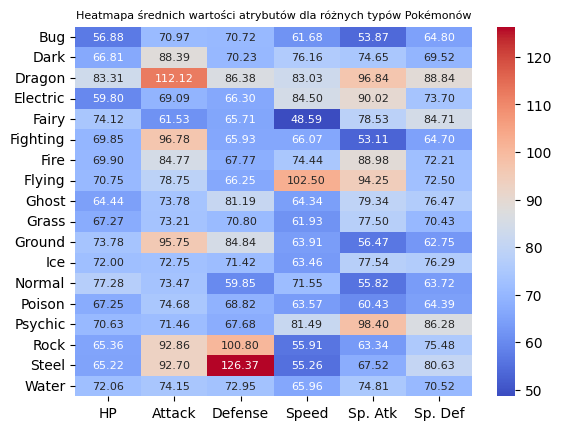

In [31]:
sns.heatmap(srednie_dane[[ 'HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']], yticklabels=srednie_dane['Type 1'], xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Heatmapa średnich wartości atrybutów dla różnych typów Pokémonów", fontsize=8)

Text(0.5, 1.0, 'Heatmapa średnich wartości Total dla różnych typów Pokémonów')

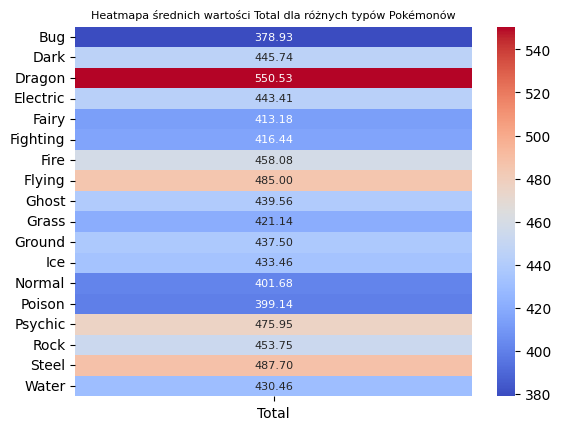

In [32]:
#Oddzielnie wyświetlamy heatmapę dla średnich wartości Total dla różnych typów Pokémonów
sns.heatmap(srednie_dane[[ 'Total']], yticklabels=srednie_dane['Type 1'], xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Heatmapa średnich wartości Total dla różnych typów Pokémonów", fontsize=8)

Z dwóch powyższych heatmap możemy zauważyć, że pokemony Dragon wyraźnie wyróżniają się od innych typów pokemonów, mają największą wartość średnią dla zmiennej Total. Mają one też największą średnią wartość zmiennej Attack. To akurat pokrywa się z wykresem udziałów, gdzie widzimy że attack i sp.attack dla tego pokemona mają największy wpływ na wartość Total.
Pokemony typu Bug mają z kolei wyraźnie najmniejszą średnią wartość Total.
Największą średnią obroną charaktrezują się pokemony Steel i akurat w tym przypadku również możemy zauwazyć z tabeli udziałów, że to wlasnie obrona ma największy wpływ na wartość Total tego pokemona. 
Zobaczmy dla przykładu jak wygląda rozkład Defense per każdy typ pokemona. Sprawdzimy, czy czasem średnia Defense dla pokemonów typów Steel nie jest "ciągnięta" w górę przez duże wartości odstające.

<Axes: xlabel='Defense', ylabel='Type 1'>

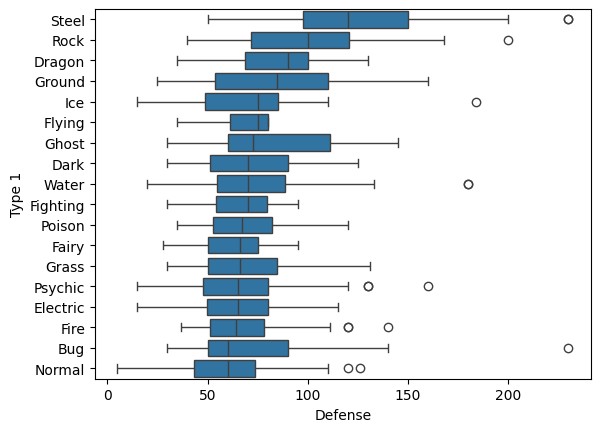

In [33]:
sns.boxplot(data=dane, y="Type 1", x="Defense", order=dane.groupby('Type 1')['Defense'].median().sort_values(ascending=False).index)

Mediana wartości obrony pokemonów typu Steel nie leży idealnie na środku, prawe pudełko jest bardziej wydłużone (dane prawostronie skośne), aczkolwiek nie jest to duża skośność, ponadto wąsy są w miarę symetryczne, zatem możemy wnioskować, że średnia wartość dla obrony dla tego typu pokemona, przedstawia całkiem realną wartość. Wykresy te potwierdzają, że faktycznie pokemony Steel mają największy atrybut obrony.

Wizualizacja zależności poszczególnego atrybuty względem wartości Total dla Pokemonów z top 3 wartości Total

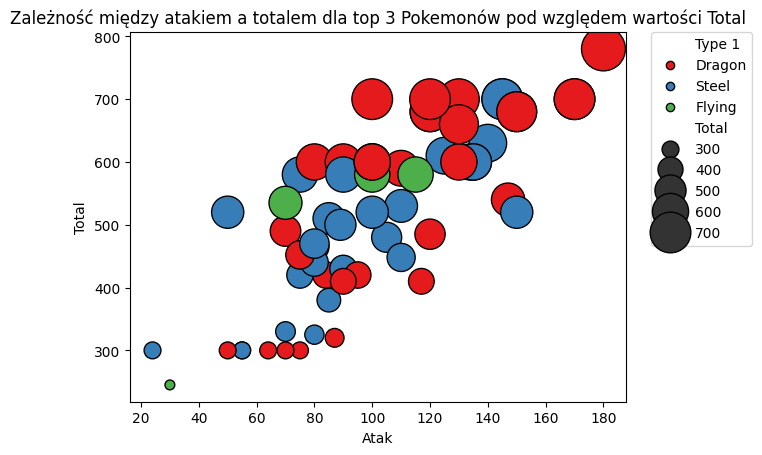

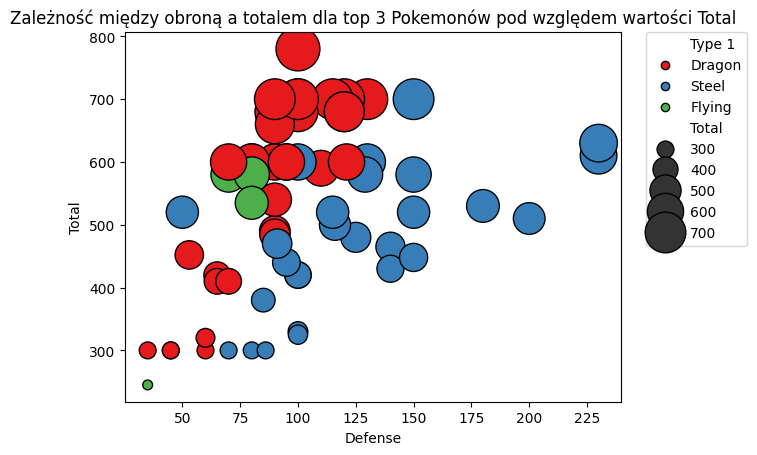

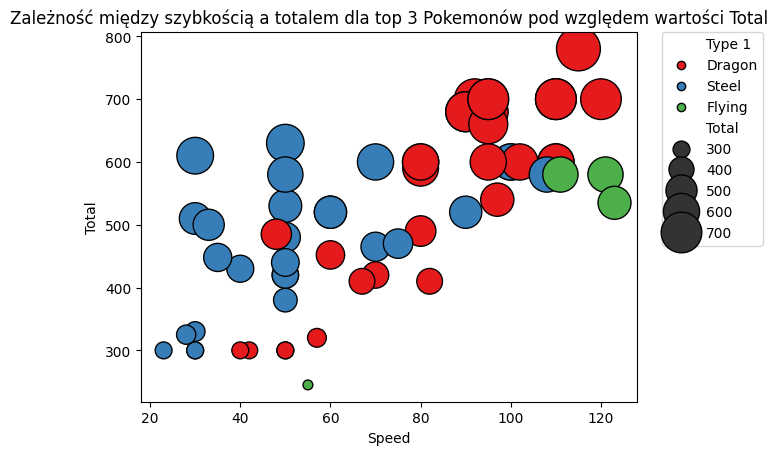

In [174]:
top3_pokemony = dane.groupby('Type 1')['Total'].mean().reset_index().nlargest(3, 'Total')
dane_wyfiltrowane = dane[dane['Type 1'].isin(top3_pokemony['Type 1'])]

sns.scatterplot(
    data=dane_wyfiltrowane,
    x="Attack",
    y="Total",
    size="Total",          
    hue="Type 1",       
    sizes=(50, 1000),     
    palette="Set1",     
    edgecolor="black"     
)

plt.xlabel("Atak")
plt.ylabel("Total")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title("Zależność między atakiem a totalem dla top 3 Pokemonów pod względem wartości Total")

plt.show()

sns.scatterplot(
    data=dane_wyfiltrowane,
    x="Defense",
    y="Total",
    size="Total",          
    hue="Type 1",       
    sizes=(50, 1000),     
    palette="Set1",     
    edgecolor="black"     
)

plt.xlabel("Defense")
plt.ylabel("Total")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title("Zależność między obroną a totalem dla top 3 Pokemonów pod względem wartości Total")

plt.show()

sns.scatterplot(
    data=dane_wyfiltrowane,
    x="Speed",
    y="Total",
    size="Total",          
    hue="Type 1",       
    sizes=(50, 1000),     
    palette="Set1",     
    edgecolor="black"     
)

plt.xlabel("Speed")
plt.ylabel("Total")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title("Zależność między szybkością a totalem dla top 3 Pokemonów pod względem wartości Total")

plt.show()

Z powyższych 3 wykresów bąbelkowych dla 3 typów pokemonów, które mają największą wartość średnią dla zmiennej Total, zauważamy że pod względem ataku, Dragon pokemony mają lekką przewagę nad pokemonami Steel, natomiast w obronie pokemony Steel wyraźnie dominują. Jeśli chodzi o prędkość, to możemy zauważyć, że pokemony Flying, których średnia prękość jest największa, wcale nie są takimi dominującymi pokemonami dla tej cechy, ponieważ są Dragony, które osiągają podobne prędkości. Ponadto widzimy, iż grupa pokemonów Flying jest mało liczną grupą, być może są to rzadkie pokemony.

Sprawdźmy liczebność pokemonów względem typu pokemona

<Axes: title={'center': 'Liczba Pokemonów w zależności od typu 1'}, xlabel='Type 1'>

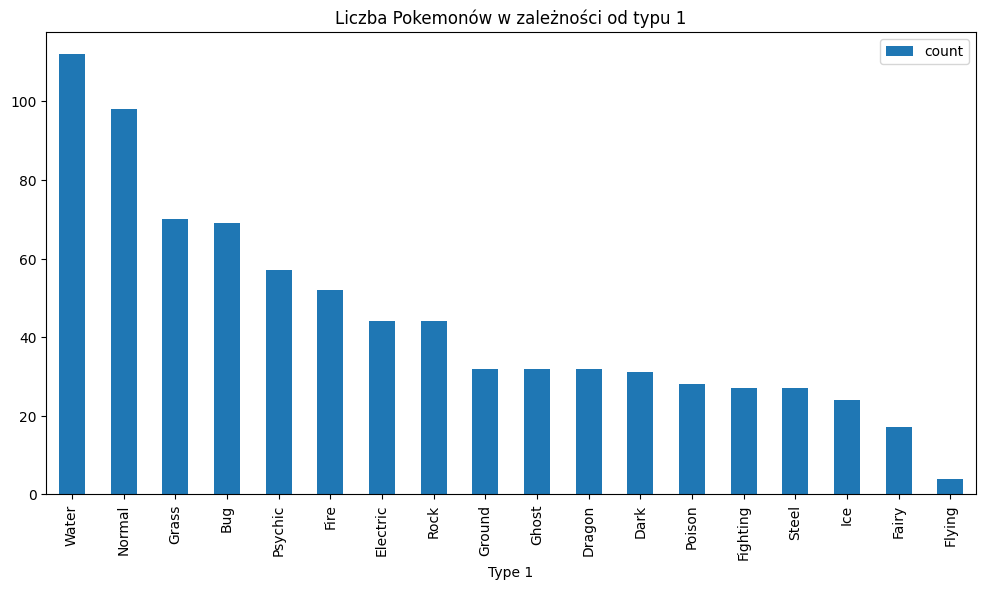

In [87]:
dane['Type 1'].value_counts().plot(kind='bar', title='Liczba Pokemonów w zależności od typu 1', legend=True, figsize=(12, 6))   

Faktycznie, pokemony Flying są najmniej liczną grupą w tym zbiorze danych.

Zweryfikujmy jak poszczególne atrybuty przedstawiają się dla różnych generacji pokemonów.

Text(0.5, 1.0, 'Heatmapa średnich wartości atrybutów dla różnych generacji Pokemonów')

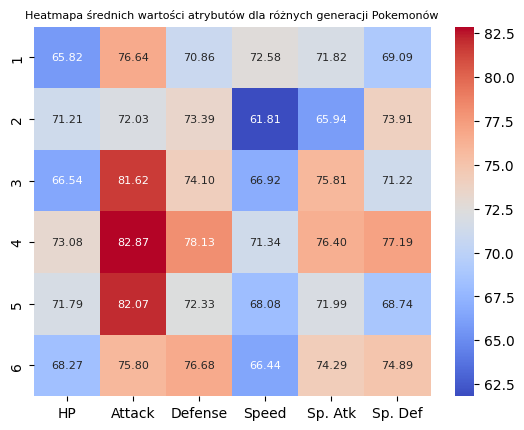

In [34]:
srednie_dane_per_generacja = dane.groupby('Generation')[zmienne_wplywajace_na_total].mean().reset_index()
sns.heatmap(srednie_dane_per_generacja[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']], yticklabels=srednie_dane_per_generacja['Generation'], xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Heatmapa średnich wartości atrybutów dla różnych generacji Pokemonów", fontsize=8)

Zauważamy, iż pokemony generacji 3ciej, 4tej i 5tej mają największą wartość średnią ataku. Natomiast pokemony generacji 2giej są najwolniejsze.
Z macierzy tej również możemy wnioskować, iż generacja 4ta pokemonów jest najlepsza. Aczkolwiek zweryfikujmy tę tezę poprzez porównanie średnich i mediany wartośći Total względem generacji.

<Axes: title={'center': 'Średnia i mediana wartości Total w zależności od generacji Pokemonów'}, xlabel='Generation'>

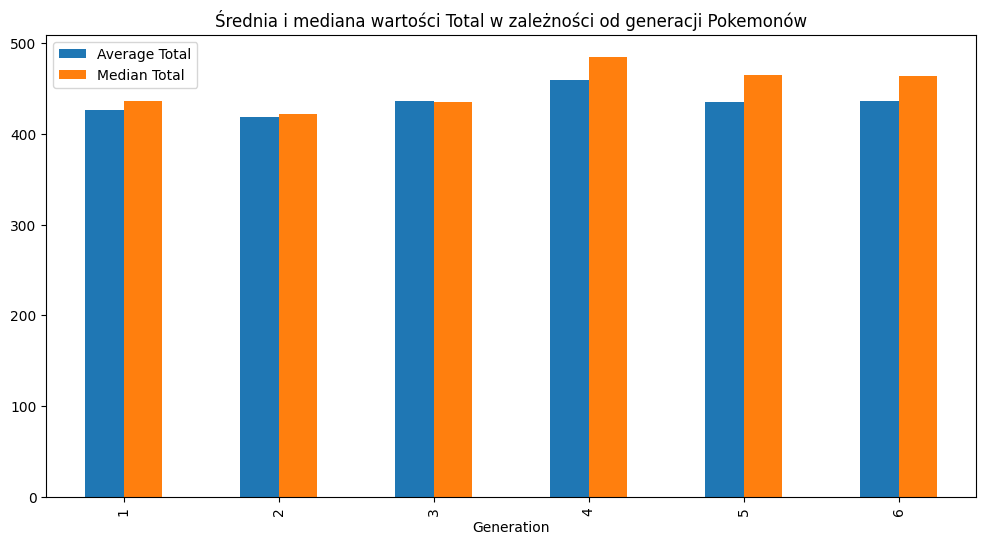

In [35]:
#Tworzymy wykres słupkowy pokazujący średnią i medianę wartości Total w zależności od generacji Pokemonów
generacje_stats = pd.DataFrame(dane.groupby('Generation')['Total'].mean().reset_index())
generacje_stats.columns = ['Generation', 'Average Total']
generacje_stats['Median Total'] = dane.groupby('Generation')['Total'].median().values
generacje_stats.plot(kind='bar', x='Generation', y=['Average Total', 'Median Total'], title='Średnia i mediana wartości Total w zależności od generacji Pokemonów', legend=True, figsize=(12, 6))

Rzeczywiście, generacja 4ta ma najwyższą wartość średnią, jak i medianę.
Warto również zauważyć, że średnie nieznacznie różnią się od mediany, aczkolwiek rozkład zmiennej Total nie jest normalny. DLa przypomnnienia narysujmy histogram dla zmiennej Total.

Text(0.5, 1.0, 'Histogram wartości Total dla wszystkich Pokemonów')

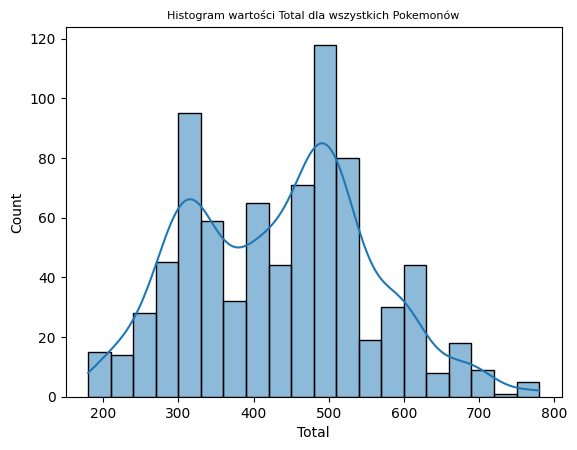

In [45]:
wykres =sns.histplot(data=dane, x='Total', bins=20, kde=True)
wykres.set_title("Histogram wartości Total dla wszystkich Pokemonów", fontsize=8)

Zobaczmy teraz jak kształtują się dane względem zmiennej Legendary

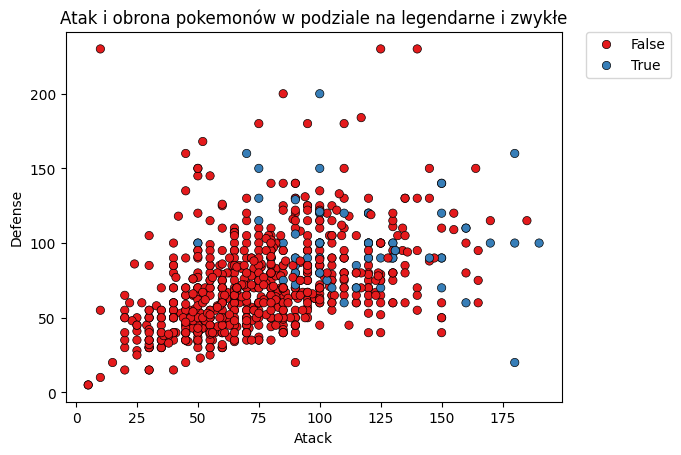

In [185]:

sns.scatterplot(
    data=dane,
    x="Attack",
    y="Defense",         
    hue="Legendary",           
    palette="Set1",     
    edgecolor="black"     
)

plt.xlabel("Atack")
plt.ylabel("Defense")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title("Atak i obrona pokemonów w podziale na legendarne i zwykłe")

plt.show()

Pokemony legendarne często mają wysokie wartości ataku i obrony, aczkolwiek wśród tych wartości są też pokemony zwykłe. Bywają też pojedyncze przypadki pokemonów legendarnych, które mają jednak wyjątkowo niski 1 atrybut (obronę), a przy tym bardzo wysoki drugi atrybut (atak).

Sprawdzimy jeszcze, jak przedstawia się cecha legendarności względem typu pokemona. Wykorzystamy do tego miarę V Cramér'a

In [187]:
tabela = pd.crosstab(dane["Type 1"], dane["Legendary"])
v_cramera = association(tabela, method="cramer")
v_cramera

0.3361928228447545

Współczynnik V Cramer'a nie jest zbyt wysoki, zatem nie ma silnego związku między typem pokemona a byciem legendarnym. Zobaczmy jak wyniki te przedstawiają się dla każdego typu pokemona.

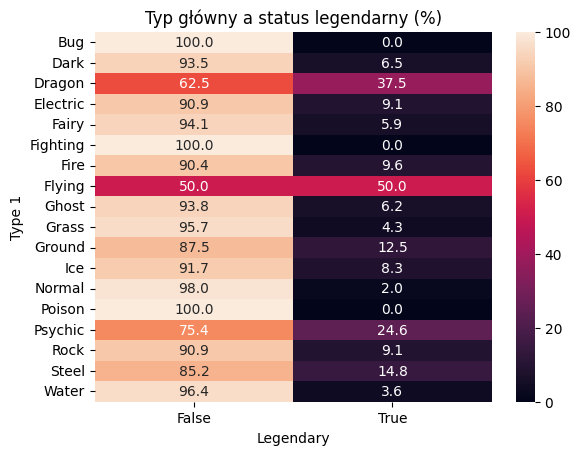

In [ ]:
# wizualizacja wsp. V Cramera
tabela_proc = pd.crosstab(dane["Type 1"], dane["Legendary"], normalize="index") * 100

sns.heatmap(tabela_proc, annot=True, fmt=".1f")

plt.title("Typ pokemona a status legendarny (%)")
plt.xlabel("Legendary")
plt.ylabel("Type 1")
plt.show()

Wyróżniają się 3 typy pokemonów: Dragon, Flying oraz Psychic, wśród których występuje najwięcej pokemnonów legendarnych. Posiadając pokemona Flying ma się największą szansę (50%) na posiadanie jednocześnie pokemona legendarnego, aczkolwiek pamiętamy z powyższych analiz, iż jest to najmniej liczna grupa pokemonów.